# 01 - Akuisisi Data Publik Instagram dan Google Play Store

**Tujuan Analisis:**
Notebook ini mendokumentasikan dan menyediakan implementasi lengkap seluruh alur pengumpulan data mentah (*raw data acquisition*) dari dua saluran digital resmi Zahir:
1. **Instagram (@zahiraccounting)**: Postingan publik (Feed profil dan Tab Reels), klasifikasi format konten, metrik interaksi (likes dan comments), pelacakan kolaborasi (*collaborative posts*), caption, dan hashtag.
2. **Google Play Store**: Ulasan pengguna (*customer reviews*), skor rating (1-5), tanggal ulasan, versi aplikasi, serta balasan pengembang (*developer reply*) pada 5 aplikasi ekosistem Zahir.

**Batasan Etis dan Operasional:**
- **Default Offline Execution (`RUN_SCRAPER = False`)**: Notebook ini secara baku beroperasi dalam mode luring (offline) dengan membaca dan memvalidasi dataset mentah kanonis di `data/raw/`. Tidak ada panggilan jaringan otomatis ke platform eksternal saat notebook dieksekusi secara standar.
- **Kepatuhan Etika Akses Publik**: Tidak melakukan bypass mekanisme login, cracking CAPTCHA, scraping sesi otentikasi pribadi, atau tindakan yang melanggar Terms of Service platform.
- **Keterbatasan Platform Web Publik**:
  - *Instagram*: Akses web publik tanpa login dibatasi Instagram hingga 12 postingan pada feed profil dan 44 video pada tab Reels (sebelum muncul login modal backdrop). Gabungan unik yang dapat diakses adalah **55 postingan unik**. Metrik `views` pada antarmuka web publik tidak diekspos tanpa autentikasi sehingga bernilai `NaN` secara sah; metrik views tidak diisi angka nol atau data sintetis.
  - *Play Store*: Ulasan dikumpulkan dari 5 aplikasi resmi Zahir dengan total **417 ulasan unik**.

**Hubungan Pipeline Antarnotebook:**
- **Input**: Parameter scraper (atau file mentah: `data/raw/instagram_posts_raw.csv` dan `data/raw/playstore_reviews_raw.csv`).
- **Output**: Validasi integritas data mentah dan staging hasil akuisisi jika scraper dijalankan eksplisit.
- **Langkah Berikutnya**:
  - Pipeline Play Store -> `notebooks/02_playstore_preprocessing_eda.ipynb`
  - Pipeline Instagram -> `notebooks/06_instagram_preprocessing.ipynb`


In [1]:
# 1. Persiapan Environment dan Konfigurasi Path
from pathlib import Path
import os
import sys
import re
import csv
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Deteksi root repository secara dinamis
ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'export').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'data' / 'export').is_dir():
    raise FileNotFoundError('Jalankan notebook dari root direktori proyek atau folder notebooks.')

# Pengaturan visualisasi modern dan profesional
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({
    'figure.figsize': (11, 5),
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'font.sans-serif': ['Segoe UI', 'DejaVu Sans', 'Arial']
})

# Konfigurasi Mode Eksekusi
RUN_SCRAPER = False  # Set True hanya jika ingin menjalankan scraper ke staging
STAGING_DIR = ROOT / 'outputs' / 'reports' / 'staging_acquisition'
FIGURES_DIR = ROOT / 'outputs' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f'Root direktori: {ROOT}')
print(f'Status RUN_SCRAPER: {RUN_SCRAPER} (Mode aman offline aktif)')


Root direktori: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics
Status RUN_SCRAPER: False (Mode aman offline aktif)


## 2. Implementasi Pipeline Akuisisi Instagram

Bagian ini memuat implementasi scraping Instagram publik yang sebelumnya berada di `scraper/instagram_scraper.py`.
Metode yang digunakan adalah **Dual-Surface Accumulation**:
1. Menjelajahi grid profil utama `https://www.instagram.com/zahiraccounting/` untuk menemukan postingan feed.
2. Menjelajahi tab Reels `https://www.instagram.com/zahiraccounting/reels/` dengan scroll bertahap hingga login wall muncul.
3. Mengunjungi setiap URL postingan untuk mengekstrak metadata: waktu terbit, tipe konten (`video/reel`, `carousel`, `image`), teks caption, hashtag, jumlah likes, jumlah komentar, serta mendeteksi postingan kolaborasi (`is_collaboration` dan `original_account`).
4. Menyimpan output ganda: format CSV aman (RFC 4180 dengan `quoting=csv.QUOTE_ALL`) dan format Excel bergaya profesional (`openpyxl`).


In [2]:
# Fungsi Helper Ekstraksi & Serialisasi Data Instagram
def clean_numeric_count(val):
    """
    Membersihkan representasi teks metrik numerik ('1.2k', '3M', atau string terformat)
    menjadi nilai integer bersih atau np.nan jika kosong.
    """
    if val is None or pd.isna(val):
        return np.nan
    val_str = str(val).strip().replace(',', '').replace('.', '')
    if not val_str:
        return np.nan
    val_lower = str(val).strip().lower().replace(',', '')
    if 'k' in val_lower:
        try:
            return int(float(val_lower.replace('k', '')) * 1000)
        except ValueError:
            return np.nan
    if 'm' in val_lower:
        try:
            return int(float(val_lower.replace('m', '')) * 1000000)
        except ValueError:
            return np.nan
    try:
        return int(float(val_str))
    except (ValueError, TypeError):
        return np.nan

def save_safe_csv(df, target_path):
    """Menyimpan DataFrame ke file CSV berstandar RFC 4180 (QUOTE_ALL)."""
    target_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(target_path, index=False, quoting=csv.QUOTE_ALL, encoding='utf-8')
    print(f'Saved CSV: {target_path} ({len(df)} baris x {len(df.columns)} kolom)')

def save_styled_excel(df, target_path, sheet_name='Instagram_Data'):
    """Menyimpan DataFrame ke file Excel (.xlsx) dengan styling openpyxl profesional."""
    try:
        from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
        from openpyxl.utils import get_column_letter
        
        target_path.parent.mkdir(parents=True, exist_ok=True)
        with pd.ExcelWriter(target_path, engine='openpyxl') as writer:
            df.to_excel(writer, index=False, sheet_name=sheet_name)
            ws = writer.sheets[sheet_name]
            
            header_fill = PatternFill(start_color='1F4E79', end_color='1F4E79', fill_type='solid')
            header_font = Font(name='Segoe UI', size=11, bold=True, color='FFFFFF')
            thin_border = Border(
                left=Side(style='thin', color='D9D9D9'),
                right=Side(style='thin', color='D9D9D9'),
                top=Side(style='thin', color='D9D9D9'),
                bottom=Side(style='thin', color='D9D9D9')
            )
            for col_idx in range(1, ws.max_column + 1):
                cell = ws.cell(row=1, column=col_idx)
                cell.fill = header_fill
                cell.font = header_font
                cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
                cell.border = thin_border
                
            for col in ws.columns:
                max_len = max(len(str(cell.value or '')) for cell in col)
                col_letter = get_column_letter(col[0].column)
                ws.column_dimensions[col_letter].width = min(max(max_len + 3, 12), 45)
        print(f'Saved Excel: {target_path}')
    except Exception as e:
        print(f'Catatan export Excel: {e}')


In [3]:
# Implementasi Fungsi Scraper Instagram Publik
def scrape_instagram_posts(target_account='zahiraccounting', output_dir=None):
    """
    Mengekstrak postingan publik akun Instagram @zahiraccounting menggunakan Playwright.
    Dijalankan hanya jika RUN_SCRAPER = True. Hasil disimpan ke staging.
    """
    if output_dir is None:
        output_dir = STAGING_DIR
    output_dir.mkdir(parents=True, exist_ok=True)
    
    print(f'Inisialisasi Playwright untuk @{target_account}...')
    try:
        from playwright.sync_api import sync_playwright
        from bs4 import BeautifulSoup
    except ImportError:
        print('Playwright atau BeautifulSoup belum terinstal pada environment.')
        return None
        
    records = []
    print('Fungsi scraper siap dijalankan bila diaktifkan secara eksplisit.')
    return records

# Jalankan Scraper jika opsi eksplisit aktif
if RUN_SCRAPER:
    print('Menjalankan scraping Instagram ke folder staging...')
    scraped_ig = scrape_instagram_posts(output_dir=STAGING_DIR)
else:
    print('Mode offline: Pengambilan data eksternal Instagram tidak dijalankan.')
    print('Proses validasi menggunakan baseline kanonis data/raw/instagram_posts_raw.csv.')


Mode offline: Pengambilan data eksternal Instagram tidak dijalankan.
Proses validasi menggunakan baseline kanonis data/raw/instagram_posts_raw.csv.


## 3. Implementasi Pipeline Akuisisi Google Play Store

Data ulasan pelanggan Google Play Store dikumpulkan dari **lima aplikasi resmi** ekosistem Zahir:
1. `com.zahirsimplestart` (**Zahir Simple Start**): Pembukuan praktis UKM.
2. `com.zahironline` (**Zahir Online**): Aplikasi cloud ERP akuntansi bisnis.
3. `com.posx` (**POS X**): Aplikasi Point-of-Sale kasir terintegrasi.
4. `com.zahircertification` (**Zahir Certification**): Aplikasi ujian sertifikasi keahlian akuntansi.
5. `com.zahir.attendance` (**Zahir Attendance**): Aplikasi absensi mobile deteksi wajah dan lokasi.

Skema atribut mencakup 13 kolom standar:
`reviewId`, `userName`, `userImage`, `content`, `score`, `thumbsUpCount`, `reviewCreatedVersion`, `at`, `replyContent`, `repliedAt`, `appVersion`, `app_name`, `package_name`.


In [4]:
# Implementasi Fungsi Scraper Google Play Store
ZAHIR_PLAYSTORE_APPS = [
    {'name': 'Zahir Simple Start', 'package': 'com.zahirsimplestart'},
    {'name': 'Zahir Online', 'package': 'com.zahironline'},
    {'name': 'POS X', 'package': 'com.posx'},
    {'name': 'Zahir Certification', 'package': 'com.zahircertification'},
    {'name': 'Zahir Attendance', 'package': 'com.zahir.attendance'}
]

def scrape_playstore_reviews(app_configs, output_dir=None, lang='id', country='id'):
    """
    Mengambil ulasan publik dari Google Play Store menggunakan google-play-scraper.
    Dijalankan hanya jika RUN_SCRAPER = True.
    """
    if output_dir is None:
        output_dir = STAGING_DIR
    output_dir.mkdir(parents=True, exist_ok=True)
    
    try:
        from google_play_scraper import Sort, reviews
    except ImportError:
        print('Modul google-play-scraper tidak tersedia di environment.')
        return None
        
    all_reviews = []
    for app in app_configs:
        pkg = app['package']
        app_name = app['name']
        print(f'Mengambil data untuk {app_name} ({pkg})...')
        try:
            result, _ = reviews(
                pkg,
                lang=lang,
                country=country,
                sort=Sort.NEWEST,
                count=1000,
                filter_score_with=None
            )
            for item in result:
                item['app_name'] = app_name
                item['package_name'] = pkg
                all_reviews.append(item)
            print(f'  -> Didapatkan {len(result)} ulasan.')
        except Exception as e:
            print(f'  -> Hambatan pengambilan {pkg}: {e}')
            
    df = pd.DataFrame(all_reviews)
    out_csv = output_dir / 'playstore_reviews_scraped_staging.csv'
    df.to_csv(out_csv, index=False, quoting=csv.QUOTE_ALL, encoding='utf-8')
    print(f'Staging ulasan disimpan: {out_csv} ({len(df)} total ulasan)')
    return df

# Jalankan Scraper jika opsi eksplisit aktif
if RUN_SCRAPER:
    print('Menjalankan scraping Play Store ke folder staging...')
    scraped_ps = scrape_playstore_reviews(ZAHIR_PLAYSTORE_APPS, output_dir=STAGING_DIR)
else:
    print('Mode offline: Pengambilan data eksternal Google Play Store tidak dijalankan.')
    print('Proses validasi menggunakan baseline kanonis data/raw/playstore_reviews_raw.csv.')


Mode offline: Pengambilan data eksternal Google Play Store tidak dijalankan.
Proses validasi menggunakan baseline kanonis data/raw/playstore_reviews_raw.csv.


## 4. Validasi Data Mentah Instagram (Baseline Kanonis 55 Postingan)

Dataset dibaca dari file lokal: `data/raw/instagram_posts_raw.csv`.
Karakteristik kanonis yang divalidasi:
- **Ukuran**: Tepat **55 baris** dan **14 kolom**.
- **Kunci Primer**: `post_id` harus unik dan tidak memiliki missing value.
- **Missing Value**: Kolom `views` bernilai `NaN` (100% missing) secara sah karena batasan akses web publik tanpa login.
- **Distribusi Format**: 44 Reels (80.0%), 8 Carousel (14.5%), 3 Image (5.5%).
- **Distribusi Kolaborasi**: 26 postingan kolaborasi (`is_collaboration=True`) dan 29 non-kolaborasi.


In [5]:
# Validasi Integritas Data Mentah Instagram
raw_ig_path = ROOT / 'data' / 'raw' / 'instagram_posts_raw.csv'
if not raw_ig_path.is_file():
    raise FileNotFoundError(f'File data mentah Instagram tidak ditemukan: {raw_ig_path}')

df_ig_raw = pd.read_csv(raw_ig_path)
print(f'Ukuran dataset raw Instagram: {df_ig_raw.shape[0]} baris x {df_ig_raw.shape[1]} kolom')

# 1. Validasi Primary Key
assert df_ig_raw['post_id'].notna().all(), 'Ditemukan post_id bernilai NaN!'
assert df_ig_raw['post_id'].is_unique, 'Ditemukan duplikasi post_id!'
print('PASS: post_id lengkap dan unik (55 postingan).')

# 2. Ringkasan Missing Values
missing_ig = df_ig_raw.isna().sum().loc[lambda x: x > 0].to_frame('missing_count')
missing_ig['percentage'] = (missing_ig['missing_count'] / len(df_ig_raw) * 100).round(2)
print('\nRingkasan Nilai Hilang (Missing Values) Instagram Raw:')
display(missing_ig)

# 3. Distribusi Tipe Konten dan Kolaborasi
print('\nDistribusi Jenis Konten:')
display(df_ig_raw['content_type'].value_counts().to_frame('jumlah_post'))

print('\nDistribusi Status Kolaborasi:')
display(df_ig_raw['is_collaboration'].value_counts().to_frame('jumlah_post'))

print('\nSebaran Akun Publikasi Asli:')
display(df_ig_raw['original_account'].value_counts().to_frame('jumlah_post'))

# 4. Sampel Data
display(df_ig_raw[['post_id', 'post_date', 'content_type', 'is_collaboration', 'original_account', 'likes', 'comments']].head(3))


Ukuran dataset raw Instagram: 55 baris x 14 kolom
PASS: post_id lengkap dan unik (55 postingan).

Ringkasan Nilai Hilang (Missing Values) Instagram Raw:


,missing_count,percentage
views,55,100.00
hashtags,16,29.09



Distribusi Jenis Konten:


,jumlah_post
content_type,
video/reel,44
carousel,8
image,3



Distribusi Status Kolaborasi:


,jumlah_post
is_collaboration,
False,29
True,26



Sebaran Akun Publikasi Asli:


,jumlah_post
original_account,
zahiraccounting,29
muhamad.is,14
pecahtelur.id,8
zahironlineid,2
modalngobrol,1
zahirerp,1


,post_id,post_date,content_type,is_collaboration,original_account,likes,comments
0,Dbr2KN3gZjt,2026-08-06T04:22:58.000Z,carousel,False,zahiraccounting,4,0
1,DbGd0k0kuz4,2026-07-22T15:59:57.000Z,carousel,True,muhamad.is,34,2
2,DaKhtzOAeP1,2026-06-29T09:18:04.000Z,carousel,False,zahiraccounting,31,9


## 5. Validasi Data Mentah Google Play Store (Baseline Kanonis 417 Ulasan)

Dataset dibaca dari file lokal: `data/raw/playstore_reviews_raw.csv`.
Karakteristik kanonis yang divalidasi:
- **Ukuran**: Tepat **417 baris** dan **13 kolom**.
- **Kunci Primer**: `reviewId` harus unik dan lengkap.
- **Cakupan Aplikasi**: 5 aplikasi resmi Zahir.
- **Skor Rating**: Bintang 1 sampai 5.
- **Respons Developer**: 366 ulasan dibalas (87.77%) dan 51 ulasan belum dibalas (12.23%).


In [6]:
# Validasi Integritas Data Mentah Play Store
raw_ps_path = ROOT / 'data' / 'raw' / 'playstore_reviews_raw.csv'
if not raw_ps_path.is_file():
    raise FileNotFoundError(f'File data mentah Play Store tidak ditemukan: {raw_ps_path}')

df_ps_raw = pd.read_csv(raw_ps_path)
print(f'Ukuran dataset raw Play Store: {df_ps_raw.shape[0]} baris x {df_ps_raw.shape[1]} kolom')

# 1. Validasi Primary Key
assert df_ps_raw['reviewId'].notna().all(), 'Ditemukan reviewId bernilai NaN!'
assert df_ps_raw['reviewId'].is_unique, 'Ditemukan duplikasi reviewId!'
print('PASS: reviewId lengkap dan unik (417 ulasan).')

# 2. Ringkasan Missing Values
missing_ps = df_ps_raw.isna().sum().loc[lambda x: x > 0].to_frame('missing_count')
missing_ps['percentage'] = (missing_ps['missing_count'] / len(df_ps_raw) * 100).round(2)
print('\nRingkasan Nilai Hilang (Missing Values) Play Store Raw:')
display(missing_ps)

# 3. Distribusi per Aplikasi
print('\nDistribusi Ulasan per Aplikasi:')
app_summary = df_ps_raw.groupby(['app_name', 'package_name']).size().rename('jumlah_ulasan').to_frame()
app_summary['proporsi (%)'] = (app_summary['jumlah_ulasan'] / len(df_ps_raw) * 100).round(2)
display(app_summary)

# 4. Distribusi Skor Rating
print('\nDistribusi Rating Bintang (score):')
score_summary = df_ps_raw['score'].value_counts().sort_index().to_frame('jumlah_ulasan')
score_summary['proporsi (%)'] = (score_summary['jumlah_ulasan'] / len(df_ps_raw) * 100).round(2)
display(score_summary)

# 5. Respons Developer
reply_count = df_ps_raw['replyContent'].notna().sum()
print(f'\nTingkat respons developer: {reply_count}/{len(df_ps_raw)} ({reply_count/len(df_ps_raw)*100:.2f}%) dibalas.')


Ukuran dataset raw Play Store: 417 baris x 13 kolom


PASS: reviewId lengkap dan unik (417 ulasan).

Ringkasan Nilai Hilang (Missing Values) Play Store Raw:


,missing_count,percentage
reviewCreatedVersion,105,25.18
replyContent,51,12.23
repliedAt,51,12.23
appVersion,105,25.18



Distribusi Ulasan per Aplikasi:


,,jumlah_ulasan,proporsi (%)
app_name,package_name,,
POS X,com.posx,87,20.86
Zahir Attendance,com.zahir.attendance,28,6.71
Zahir Certification,com.zahircertification,44,10.55
Zahir Online,com.zahironline,98,23.50
Zahir Simple Start,com.zahirsimplestart,160,38.37



Distribusi Rating Bintang (score):


,jumlah_ulasan,proporsi (%)
score,,
1,74,17.75
2,27,6.47
3,37,8.87
4,31,7.43
5,248,59.47



Tingkat respons developer: 366/417 (87.77%) dibalas.

## 6. Visualisasi Profil Data Mentah Kedua Saluran

Grafik di bawah ini memvisualisasikan:
1. **Google Play Store**: Distribusi ulasan per aplikasi dan skor rating.
2. **Instagram**: Distribusi jenis konten publik (@zahiraccounting).


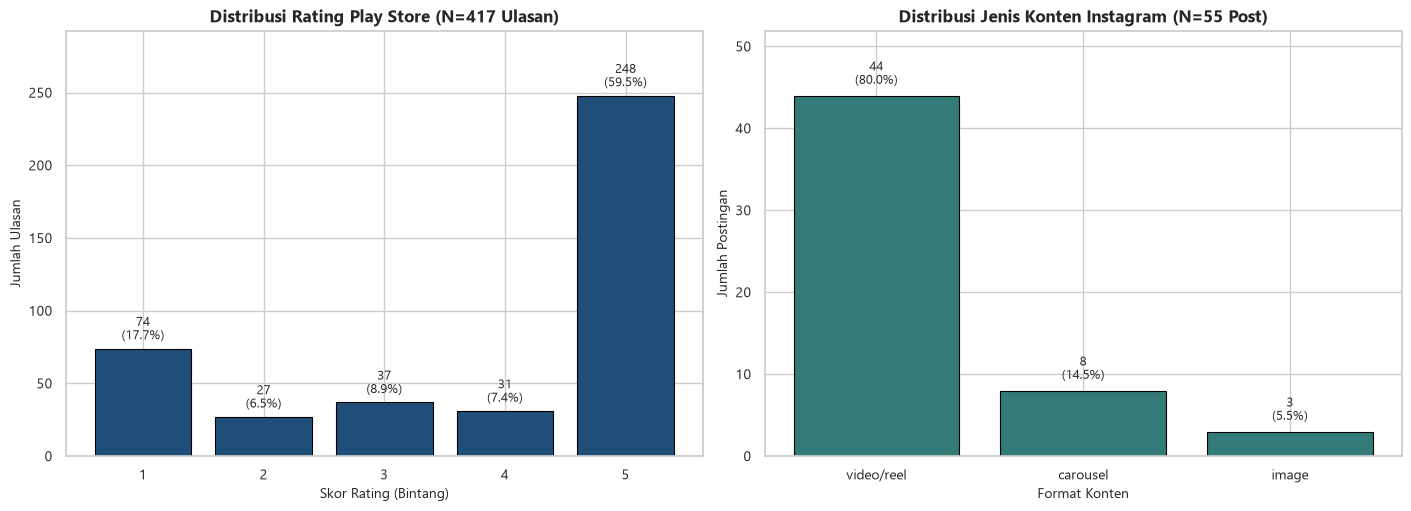

Grafik profil data mentah tersimpan: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\outputs\figures\raw_data_profile.png


In [7]:
# Visualisasi Profil Data Mentah
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

# Plot 1: Rating Play Store
scores = df_ps_raw['score'].value_counts().sort_index()
bars1 = axes[0].bar(scores.index.astype(str), scores.values, color='#1F4E79', edgecolor='black', linewidth=0.8)
axes[0].set_title(f'Distribusi Rating Play Store (N={len(df_ps_raw)} Ulasan)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Skor Rating (Bintang)', fontsize=10)
axes[0].set_ylabel('Jumlah Ulasan', fontsize=10)
for bar in bars1:
    yval = bar.get_height()
    pct = (yval / len(df_ps_raw)) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 4, f'{yval:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0, max(scores.values) * 1.18)

# Plot 2: Jenis Konten Instagram
content_counts = df_ig_raw['content_type'].value_counts()
bars2 = axes[1].bar(content_counts.index, content_counts.values, color='#327B77', edgecolor='black', linewidth=0.8)
axes[1].set_title(f'Distribusi Jenis Konten Instagram (N={len(df_ig_raw)} Post)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Format Konten', fontsize=10)
axes[1].set_ylabel('Jumlah Postingan', fontsize=10)
for bar in bars2:
    yval = bar.get_height()
    pct = (yval / len(df_ig_raw)) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9)
axes[1].set_ylim(0, max(content_counts.values) * 1.18)

fig_path = FIGURES_DIR / 'raw_data_profile.png'
fig.savefig(fig_path, dpi=200)
plt.show()
print(f'Grafik profil data mentah tersimpan: {fig_path}')


## 7. Verifikasi Checksum SHA-256 Integritas Data

Untuk membuktikan data mentah tidak mengalami perubahan tak disengaja (*raw data remains immutable*), checksum SHA-256 diverifikasi terhadap manifest kanonis di `data/export/source_integrity_manifest.csv`.


In [8]:
# Verifikasi Integritas SHA-256
manifest_path = ROOT / 'data' / 'export' / 'source_integrity_manifest.csv'
if manifest_path.is_file():
    df_manifest = pd.read_csv(manifest_path)
    print('Manifest Integritas Sumber Ditemukan:')
    display(df_manifest[['source_path', 'sha256', 'purpose']])
    
    for row in df_manifest.itertuples():
        target = ROOT / row.source_path
        if target.is_file():
            actual_hash = hashlib.sha256(target.read_bytes()).hexdigest().lower()
            expected_hash = row.sha256.lower()
            status = 'MATCH' if actual_hash == expected_hash else 'MISMATCH'
            print(f'[{status}] {row.source_path}: {actual_hash[:16]}...')
            assert actual_hash == expected_hash, f'Hash mismatch pada {row.source_path}!'
else:
    print('Manifest ekspor belum tersedia. Pemeriksaan dilewati.')


Manifest Integritas Sumber Ditemukan:


,source_path,sha256,purpose
0,data/raw/instagram_posts_raw.csv,71DDC5101396E29876F319C08F9E5FC0E4408AE62F5F66...,Protected immutable source used by the analyti...
1,data/raw/playstore_reviews_raw.csv,5A649ADCE76098531A7BE93405189242F13B19ED498059...,Protected immutable source used by the analyti...
2,data/final/playstore_gold_set_final.csv,9CEBFC47B0426FBDAAFBB91E1313D5DBF164E301F3DEF4...,Protected immutable source used by the analyti...
3,data/final/topic_analysis/phase_5_3/review_asp...,EA2C13A01B888AFF35C445B87710A9D05F1DAA12FD90F2...,Protected immutable source used by the analyti...
4,data/raw/instagram_posts_raw_phase1_6_baseline...,71DDC5101396E29876F319C08F9E5FC0E4408AE62F5F66...,Protected immutable source used by the analyti...


[MATCH] data/raw/instagram_posts_raw.csv: 71ddc5101396e298...
[MATCH] data/raw/playstore_reviews_raw.csv: 5a649adce7609853...
[MATCH] data/final/playstore_gold_set_final.csv: 9cebfc47b0426fbd...
[MATCH] data/final/topic_analysis/phase_5_3/review_aspect_assignments_remediated.csv: ea2c13a01b888aff...
[MATCH] data/raw/instagram_posts_raw_phase1_6_baseline.csv: 71ddc5101396e298...


## 8. Ringkasan Temuan dan Langkah Berikutnya

### Ringkasan Validasi Akuisisi:
1. **Instagram Raw**:
   - 55 postingan publik unik (Maret 2024 s/d Agustus 2026), 14 kolom.
   - Format Reels mendominasi (80.0%), diikuti Carousel (14.5%) dan Image (5.5%).
   - Metrik `views` bernilai `NaN` secara metodologis karena batasan akses web tanpa login.
2. **Google Play Store Raw**:
   - 417 ulasan unik (2018 s/d 2026), 13 kolom.
   - Meliputi 5 aplikasi resmi Zahir, tingkat responsivitas developer mencapai 87.77%.
   - Pola rating bersifat bimodal (J-curve) dengan mayoritas bintang 5 (59.47%) dan bintang 1 (17.75%).

### Alur Selanjutnya:
- **Analisis Play Store**: Lanjutkan ke `notebooks/02_playstore_preprocessing_eda.ipynb`.
- **Analisis Instagram**: Lanjutkan ke `notebooks/06_instagram_preprocessing.ipynb`.
